In [1]:
import requests
import string
from bs4 import BeautifulSoup
from pprint import pprint

import numpy as np
from scipy.stats import describe
import matplotlib.pyplot as plt

from nltk import word_tokenize, PorterStemmer, download
from nltk.corpus import stopwords

from wordcloud import WordCloud

from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.naive_bayes import BernoulliNB, MultinomialNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import cross_validate

from seaborn import heatmap

Documentation: 
- https://beautiful-soup-4.readthedocs.io/en/latest/
- https://requests.readthedocs.io/en/latest/

In [2]:
categories = [
    ("Tech", "https://finance.yahoo.com/topic/tech/"),
    ("Stock Market News", "https://finance.yahoo.com/topic/stock-market-news"),
    ("Cryptocurrency", "https://finance.yahoo.com/topic/crypto/")
]

In [29]:
download('punkt') # Pretrained tokenizers
download('stopwords')



[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\seyye\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\seyye\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [28]:
stop_words = set(stopwords.words('english'))
punctuation = set(string.punctuation)
stemmer = PorterStemmer()

print(punctuation)
print(stop_words) 

{'+', ';', '=', '!', ':', '@', '`', ',', '[', '>', '|', '}', '<', ')', '\\', '&', '-', '*', '$', '"', '^', '#', '_', '/', '?', '.', ']', '{', '(', "'", '%', '~'}
{'needn', 'as', "they'll", 'couldn', 'just', "shouldn't", 'few', 'above', 'ours', "we're", "that'll", 'once', 'they', 'be', 'hadn', 'those', 'been', 'most', "you'll", 'both', 'where', "i'm", 'down', "should've", "he'll", 'through', 'the', "wouldn't", 'y', 'until', 'at', 'aren', 'me', "aren't", 'there', 'what', 'not', "they're", 'some', 'or', "it's", "i've", 'after', 'up', 'how', 'an', 'in', 'are', 'my', 'further', 'this', 'all', 'yours', 'whom', 'hers', "she'll", 'into', 'these', 'don', "shan't", 've', 'shan', "hadn't", "we'd", "we've", "mustn't", 'was', "she's", 'am', 'out', "you've", 'having', 'very', 'only', 'under', 'he', 'our', 'had', 'by', 'with', 'mightn', 'doing', "mightn't", 'did', 'itself', 'other', 'she', "he's", 'to', 'i', 'shouldn', 'while', 'has', 'can', 'have', 'who', 'more', 'myself', 'for', 'is', 'yourself', '

In [5]:
def valid_word(word):
    return (word not in stop_words) and (word not in punctuation) and (not word.isdigit())

In [12]:
all_text = dict()
for name, url in categories:
    
    req = requests.get(url, headers = {'User-agent': 'Mozilla/5.0 (Windows NT 6.1; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/64.0.3282.186 Safari/537.36'})
    soup = BeautifulSoup(req.text, 'html.parser')
    articles = soup.find('div',{"class":"topic-stream"}).find_all('a', {"class": "subtle-link"})
    article_links = [article.get("href") for article in articles]
    print(article_links)
    scraped_text = dict()
    
    for article_link in article_links[::2]:
        print(article_link)
        req = requests.get(article_link, headers = {'User-agent': 'Mozilla/5.0 (Windows NT 6.1; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/64.0.3282.186 Safari/537.36'})
        if not req.ok: 
            print(f"Bad Request: {article_link}")
            continue

        soup = BeautifulSoup(req.text)                
        title = soup.title.string
        content = soup.find("div", {"class": "bodyItems-wrapper"}).find_all("p")
        content_text = '\n'.join([p.text for p in content])
        scraped_text[title] = ' '.join([stemmer.stem(word) 
                                        for word in word_tokenize(content_text) 
                                        if valid_word(word)])    

    all_text[name] = scraped_text

['https://finance.yahoo.com/news/does-sirius-xm-offer-value-060454993.html', 'https://finance.yahoo.com/news/does-sirius-xm-offer-value-060454993.html', 'https://finance.yahoo.com/news/does-ionqs-3-5-billion-060000784.html', 'https://finance.yahoo.com/news/does-ionqs-3-5-billion-060000784.html', 'https://finance.yahoo.com/news/inside-yahoo-finance-invest-2025-the-top-question-that-must-be-answered-133058599.html', 'https://finance.yahoo.com/news/inside-yahoo-finance-invest-2025-the-top-question-that-must-be-answered-133058599.html', 'https://finance.yahoo.com/news/standard-chartered-sets-sights-hong-045659785.html', 'https://finance.yahoo.com/news/standard-chartered-sets-sights-hong-045659785.html', 'https://finance.yahoo.com/news/did-ai-integration-major-acquisitions-042150241.html', 'https://finance.yahoo.com/news/did-ai-integration-major-acquisitions-042150241.html', 'https://finance.yahoo.com/news/exploring-fiverr-fvrr-valuation-strong-021254710.html', 'https://finance.yahoo.com/ne

https://finance.yahoo.com/news/inside-xais-organizational-chart-whos-093501369.html
https://finance.yahoo.com/news/amazon-pinterest-40-tech-companies-090002168.html
https://finance.yahoo.com/news/musks-starlink-could-help-remote-075306520.html
https://finance.yahoo.com/news/roche-pairs-zealand-pharma-obesity-061742621.html
https://finance.yahoo.com/news/chinese-users-turn-off-exchange-055101259.html
https://finance.yahoo.com/news/chip-design-firm-skyechip-said-032620344.html
https://finance.yahoo.com/news/salesforce-invest-1-billion-singapore-024747998.html
https://finance.yahoo.com/news/oil-prices-rise-weak-dollar-013810250.html
https://finance.yahoo.com/news/ron-barons-firm-sold-tesla-171315551.html
https://finance.yahoo.com/news/billionaire-agarwal-may-invest-us-234251057.html
https://finance.yahoo.com/news/global-companies-eye-more-us-222041213.html
https://finance.yahoo.com/news/kimmeridge-eyes-more-canada-oil-210341130.html
https://finance.yahoo.com/news/time-come-ramp-u-gas-2049

https://finance.yahoo.com/news/intel-names-lip-bu-tan-211935852.html
https://finance.yahoo.com/news/morning-bid-finally-bounce-wall-210646439.html
https://finance.yahoo.com/news/p-500-gains-losses-today-210507832.html
https://finance.yahoo.com/news/intel-appoints-lip-bu-tan-as-ceo-stock-jumps-11-210407481.html
https://finance.yahoo.com/news/stock-day-intel-spikes-5-210333967.html
https://finance.yahoo.com/news/american-eagle-nyse-aeo-reports-205553204.html
https://finance.yahoo.com/news/kohl-stock-keeps-falling-wall-204336486.html
https://finance.yahoo.com/news/phreesia-nyse-phr-posts-better-204036953.html
https://finance.yahoo.com/news/beautyhealth-nasdaq-skin-beats-q4-203230954.html
https://finance.yahoo.com/news/uipath-nyse-path-posts-q4-202958155.html
https://finance.yahoo.com/news/sentinelone-nyse-exceeds-q4-expectations-202509139.html
https://finance.yahoo.com/news/calavo-nasdaq-cvgw-misses-q4-202024805.html
https://finance.yahoo.com/news/adobe-nasdaq-adbe-surprises-q1-201934535.

https://finance.yahoo.com/news/bitcoin-miner-bitdeer-increases-btc-163238212.html
https://finance.yahoo.com/news/bitcoin-rebounds-rosy-inflation-report-161917080.html
https://finance.yahoo.com/news/binance-labs-backed-network-hemi-160000418.html
https://finance.yahoo.com/news/most-important-4-words-president-153900062.html
Bad Request: https://finance.yahoo.com/news/most-important-4-words-president-153900062.html
https://finance.yahoo.com/news/senate-poised-advance-landmark-crypto-152830350.html
Bad Request: https://finance.yahoo.com/news/senate-poised-advance-landmark-crypto-152830350.html
https://finance.yahoo.com/news/binance-nets-biggest-ever-crypto-151912149.html
Bad Request: https://finance.yahoo.com/news/binance-nets-biggest-ever-crypto-151912149.html
https://finance.yahoo.com/news/uae-company-invests-2b-binance-151238020.html
https://finance.yahoo.com/news/bitcoin-where-does-now-150946461.html
https://finance.yahoo.com/news/binance-says-abu-dhabis-mgx-150851375.html
https://fin

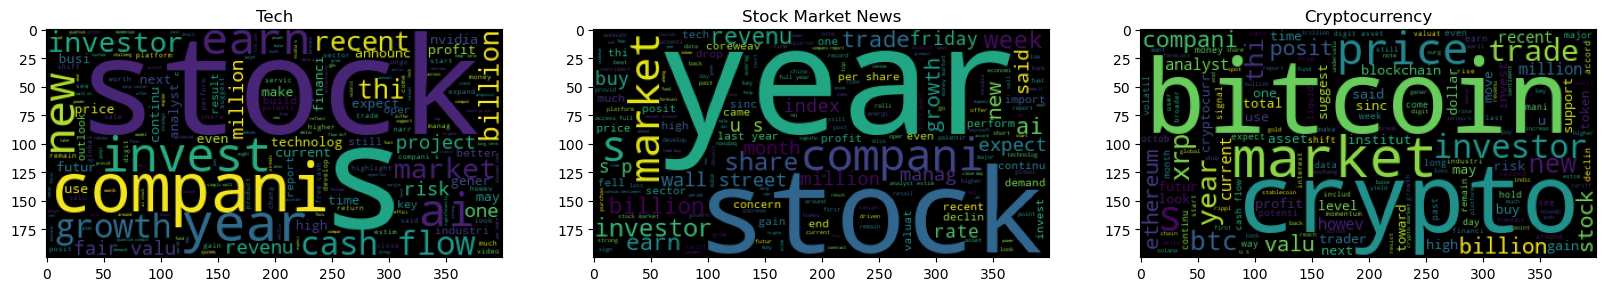

In [13]:
fig, axs = plt.subplots(ncols=3, figsize=(20, 15))

for (cat, articles), ax in zip(all_text.items(), axs):
    wc = WordCloud().generate(' '.join(articles.values()))
    ax.imshow(wc)
    ax.set_title(cat)

In [32]:
all_titles = dict()
all_bow = dict()

bow_model = CountVectorizer()

for cat, articles in all_text.items():
    titles, corpus = zip(*articles.items())
    all_titles[cat] = titles

    all_bow[cat] = bow_model.fit_transform(corpus)
all_titles, all_bow

({'Tech': ('Does Sirius XM Offer Value After Its New Digital Content Push?',
   "Does IonQ's $3.5 Billion Cash Hoard Make It the Most Dominant Force in Quantum Computing?",
   'Inside Yahoo Finance Invest 2025: The top question that must be answered',
   'Standard Chartered Sets Sights on Hong Kong as Core of Blockchain Ambitions',
   "Did AI Integration and Major Acquisitions Just Shift Rocket Companies' (RKT) Investment Narrative?",
   'Exploring Fiverr (FVRR) Valuation After Strong Earnings and AI-Driven Growth Signals',
   'FuriosaAI CEO on Business Strategy, AI Policy',
   "Nvidia's Quiet Move Into Quantum Computing Could Reshape the Next Frontier of AI",
   'Does SkyWater’s Quantum Partnership and Q3 Beat Redefine the Market Outlook for SKYT?',
   'Is TELUS Fairly Priced After Recent Investments in Wireless Infrastructure?',
   'Is Netflix Still Worth the Hype After a 9.5% Dip?',
   'Assessing Metaplanet’s Value After Strong Gains and Blockchain Partnership News',
   'UMH Propert

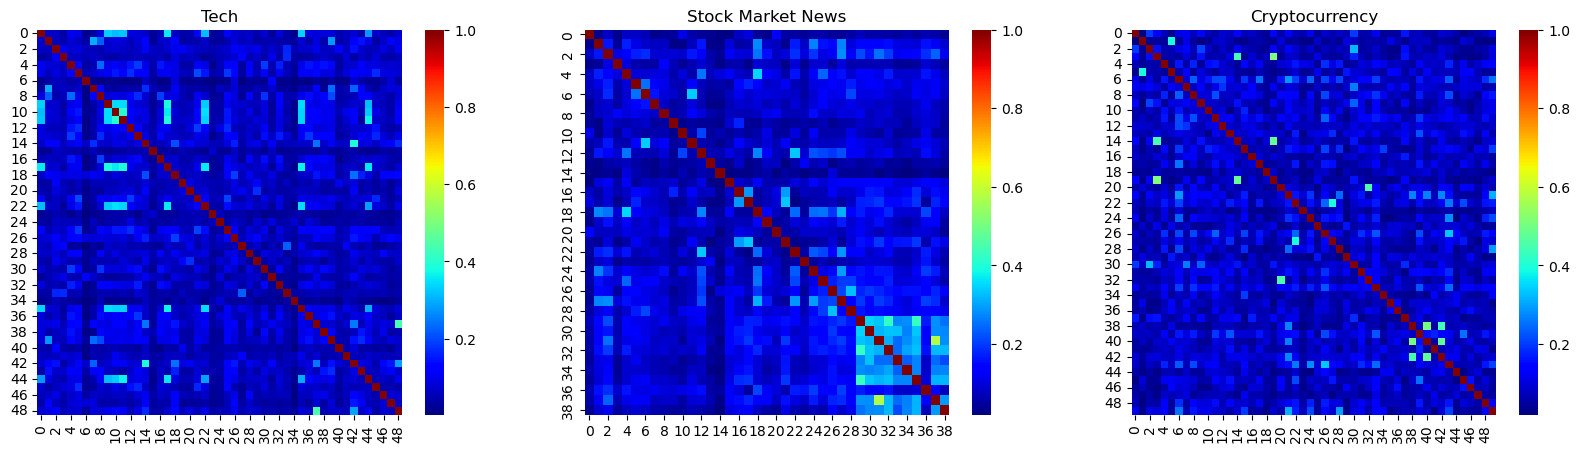

In [15]:
fig, axs = plt.subplots(ncols=3, figsize=(20, 5))

all_sim = dict()
tfidf_model = TfidfTransformer()

for (cat, bow), ax in zip(all_bow.items(), axs):
    tfidf = tfidf_model.fit_transform(bow)
    sim = cosine_similarity(tfidf)
    
    all_sim[cat] = sim
    
    heatmap(sim, cmap="jet", ax=ax)
    ax.set_title(cat)

In [16]:
top_n = 5
all_closest = dict()

for cat, sim in all_sim.items():

    # in a real world scenario, don't create too many variables like this other than for testing purposes.
    sim_array = np.tril(sim, k=-1).reshape(-1)
    # what is happening with this indexing?
    closest_idxs = np.argsort(sim_array)[-1:-(top_n + 1):-1]
    closest_coords = np.unravel_index(closest_idxs, sim.shape)

    # why not zip it will the above?
    titles = all_titles[cat]
    all_closest[cat] = [(titles[ix], titles[iy], sim[ix, iy]) for ix, iy in zip(*closest_coords)]

pprint(all_closest)

{'Cryptocurrency': [('Is Bilibili’s Recent Pullback a Chance After Digital '
                     'Media Partnerships?',
                     'Should Investors Reassess DXC Technology After Takeover '
                     'Rumors and a 33.4% Share Price Decline?',
                     np.float64(0.5148498018108378)),
                    ('Prediction: XRP (Ripple) Will Surge Past This Price by '
                     '2029',
                     '3 Bearish Signals for XRP',
                     np.float64(0.5076795893736119)),
                    ('Is Bilibili’s Recent Pullback a Chance After Digital '
                     'Media Partnerships?',
                     'Assessing Metaplanet’s Value After Strong Gains and '
                     'Blockchain Partnership News',
                     np.float64(0.4855161674180235)),
                    ('XRP Will Soon Spike 69% If History Repeats Itself',
                     'Prediction: XRP (Ripple) Will Surge Past This Price by '
             

In [36]:
small_bow = CountVectorizer(max_features=100)
cats = list(all_text.keys())
# what is this `start` argument to `sum`?
y = np.array(sum([[cats.index(cat)]*len(articles) 
                  for cat, articles in all_text.items()], 
             start=[]))
X = small_bow.fit_transform(sum([list(articles.values()) 
                                 for _, articles in all_text.items()],
                                start=[]))
y,X

(array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2]),
 <Compressed Sparse Row sparse matrix of dtype 'int64'
 	with 5227 stored elements and shape (138, 100)>)

In [18]:
def fit_and_score(clf, X, y):
    scores = cross_validate(clf, X, y, cv=5)["test_score"]
    return {
        "mean": np.mean(scores), 
        "min": np.min(scores), 
        "max": np.max(scores)
    }

In [19]:
fit_and_score(RandomForestClassifier(random_state=42), X, y)

{'mean': np.float64(0.6973544973544973),
 'min': np.float64(0.5357142857142857),
 'max': np.float64(0.8518518518518519)}

In [20]:
fit_and_score(BernoulliNB(force_alpha=True), X, y)

{'mean': np.float64(0.7039682539682539),
 'min': np.float64(0.5714285714285714),
 'max': np.float64(0.8214285714285714)}

In [21]:
fit_and_score(MultinomialNB(force_alpha=True), X, y)

{'mean': np.float64(0.6894179894179895),
 'min': np.float64(0.5714285714285714),
 'max': np.float64(0.8148148148148148)}